#### WRITER ID DICTIONARY

In [ ]:
from glob import glob
import os
import re


def parse_writer_id(filename):
    # Regex to match 'id_...' at the start of filenames
    id_pattern = re.compile(r'(id_[A-Za-z0-9]+)')
    match = id_pattern.search(filename)
    if match:
        file_id = match.group(1)
    return file_id


def build_writer_dict(root_dir):
    # Maps writer ID to list of all their image paths
    writer_dict = {}
    for subdir in ['Paper', 'Tablet']:
        full_path = os.path.join(root_dir, subdir)
        for img_path in glob(os.path.join(full_path, '*.png')):
            writer_id = parse_writer_id(os.path.basename(img_path))
            writer_dict.setdefault(writer_id, []).append(img_path)

    return writer_dict

In [2]:
writer_dict = build_writer_dict(root_dir="/workspaces/hotel_booking_demand_analysis/Training_images")
writer_dict

{'id_SC47b': ['/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC47b_paper_149_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC47b_paper_148_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC47b_paper_150_page_1.png'],
 'id_SC92': ['/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC92_paper_088_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC92_paper_089_page_1.png'],
 'id_SC68': ['/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC68_paper_093_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC68_paper_095_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_SC68_paper_094_page_1.png'],
 'id_10': ['/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_10_paper_045_page_1.png',
  '/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_1

### Crop Image to text area and remove gridlines

In [ ]:
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
import numpy as np
import matplotlib.pyplot as plt


def auto_detect_image_type(image_path):
    """
    Automatically detects if an image has dark background with light text
    
    Args:
        image_path: Path to the input image
        
    Returns:
        Boolean indicating if the image should be inverted (True for dark background)
    """
    img = Image.open(image_path)
    gray = ImageOps.grayscale(img)
    img_array = np.array(gray)
    
    # Calculate average brightness
    avg_brightness = np.mean(img_array)
    
    # If average brightness is below 128 (middle of 0-255 range),
    # it's likely a dark background image
    return avg_brightness < 128

def crop_to_text(image_path, padding=20, threshold=240, contain_grid=False, grid_detection_threshold=235, invert=False):
    """
    Crops an image to keep only the text regions with some padding using PIL.
    Can also remove grid lines if requested.
    
    Args:
        image_path: Path to the input image
        padding: Number of pixels to add around the text region (default: 20)
        threshold: Pixel value to consider as text (0-255, higher values detect lighter text)
        contain_grid: If True, keeps the grid lines. If False, removes them (default: False)
        grid_detection_threshold: Threshold for detecting grid lines (used only if contain_grid=False)
        invert: If True, assumes dark background with light text and grid (default: False)
        
    Returns:
        Cropped image with or without grid lines
    """
    # Open the image
    img = Image.open(image_path)
    
    # Convert to grayscale
    gray = ImageOps.grayscale(img)
    
    # Convert to numpy array for processing
    img_array = np.array(gray)
    
    # Invert the image if it has a dark background with light text
    if invert:
        img_array = 255 - img_array
    
    # Remove grid lines if requested
    if not contain_grid:
        # Create a mask where grid lines are likely to be (light colored pixels)
        grid_mask = img_array > grid_detection_threshold
        
        # Create a cleaned image array (remove grid lines)
        img_array_cleaned = img_array.copy()
        img_array_cleaned[grid_mask] = 255  # Set grid pixels to white
        
        # Apply slight blur to smooth out removed grid artifacts
        cleaned_img = Image.fromarray(img_array_cleaned.astype(np.uint8))
        cleaned_img = cleaned_img.filter(ImageFilter.GaussianBlur(0.5))
        
        # Update array for further processing
        img_array = np.array(cleaned_img)
    
    # Find all text pixels (non-white pixels)
    text_pixels = np.where(img_array < threshold)
    
    # If no text found, return original or cleaned image
    if len(text_pixels[0]) == 0 or len(text_pixels[1]) == 0:
        print("No text detected in the image.")
        if not contain_grid:
            return Image.fromarray(img_array.astype(np.uint8))
        return img
    
    # Find bounding box
    y_min, y_max = np.min(text_pixels[0]), np.max(text_pixels[0])
    x_min, x_max = np.min(text_pixels[1]), np.max(text_pixels[1])
    
    # Add padding
    y_min = max(0, y_min - padding)
    y_max = min(img_array.shape[0], y_max + padding)
    x_min = max(0, x_min - padding)
    x_max = min(img_array.shape[1], x_max + padding)
    
    # Crop the image
    if not contain_grid:
        processed_img = Image.fromarray(img_array.astype(np.uint8))
        cropped_img = processed_img.crop((x_min, y_min, x_max, y_max))
    else:
        if invert:
            # Convert back to original coloring scheme for display
            img_array_original = 255 - img_array
            processed_img = Image.fromarray(img_array_original.astype(np.uint8))
            cropped_img = processed_img.crop((x_min, y_min, x_max, y_max))
        else:
            cropped_img = img.crop((x_min, y_min, x_max, y_max))
    
    # Revert back to original coloring scheme if inverted and not containing grid
    # if invert and not contain_grid:
    #    cropped_img = ImageOps.invert(cropped_img)
    
    return cropped_img

def display_result(original_image_path, processed_image):
    """
    Displays the original and processed images side by side
    """
    original = Image.open(original_image_path)
    
    plt.figure(figsize=(15, 7))
    
    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(processed_image, cmap='gray')
    
    # Set appropriate title based on whether grid was removed
    if hasattr(processed_image, 'grid_removed') and processed_image.grid_removed:
        plt.title('Processed Image (Grid Removed & Cropped)')
    else:
        plt.title('Cropped Image')
    
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Print the dimensions
    original_size = original.size
    processed_size = processed_image.size
    print(f"Original dimensions: {original_size[1]} x {original_size[0]}")
    print(f"Processed dimensions: {processed_size[1]} x {processed_size[0]}")
    original_area = original_size[0] * original_size[1]
    processed_area = processed_size[0] * processed_size[1]
    print(f"Reduced by: {100 - (processed_area / original_area * 100):.2f}% in area")

def enhance_text_contrast(image, contrast_factor=1.5):
    """
    Enhances the contrast of the text to make it stand out more
    """
    # Convert to PIL Image if it's not already
    if not isinstance(image, Image.Image):
        image = Image.fromarray(image.astype(np.uint8))
    
    # Enhance contrast
    from PIL import ImageEnhance
    enhancer = ImageEnhance.Contrast(image)
    enhanced_img = enhancer.enhance(contrast_factor)
    
    return enhanced_img



if __name__ == "__main__":
    # Replace with the path to your uploaded image

    #image_path = "/workspaces/hotel_booking_demand_analysis/Training_images/Paper/id_1_paper_040_page_1.png"
    # image_path = "/workspaces/hotel_booking_demand_analysis/Training_images/Tablet/id_1_Tablet_043_page_1.png"
    image_path = "/workspaces/hotel_booking_demand_analysis/Training_images/Tablet/id_43_Tablet_049_page_1.png" 
    
    # Auto-detect if image has dark background with light text
    is_inverted = auto_detect_image_type(image_path)
    print(f"Auto-detected image type: {'Dark background' if is_inverted else 'Light background'}")
    
    # Process with grid removal
    processed_no_grid = crop_to_text(
        image_path, 
        padding=20, 
        threshold=210 if not is_inverted else 40,  # Adjust based on image type
        contain_grid=False,  # Remove grid lines
        grid_detection_threshold=205 if not is_inverted else 30,  # Adjust based on image type
        invert=is_inverted  # Use auto-detected value
    )

    # padding=20, 
    # text_threshold=205,  # Adjust for your handwriting darkness
    # grid_detection_threshold=205
    
    # Optional: enhance contrast to make text stand out better
    processed_no_grid = enhance_text_contrast(processed_no_grid, contrast_factor=1.5)
    
    # Save the processed image
    processed_no_grid.save("processed_no_grid.jpg")
    
    # Display results
    display_result(image_path, processed_no_grid)
    
    print("Processed image (no grid) saved as 'processed_no_grid.jpg'")



    '''
    # Process without grid removal (just cropping)
    processed_with_grid = crop_to_text(
        image_path, 
        padding=20, 
        threshold=220 if not is_inverted else 40,  # Adjust based on image type
        contain_grid=True,  # Keep grid lines
        invert=is_inverted  # Use auto-detected value
    )
    
    # Save the processed image
    processed_with_grid.save("processed_with_grid.jpg")
    
    # Display results
    display_result(image_path, processed_with_grid)
    
    print("Processed image (with grid) saved as 'processed_with_grid.jpg'")
    '''

### Denoise

In [ ]:
# sudo apt update
# sudo apt install libgl1

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os


def denoise_handwritten_text(image_path, output_dir="denoised_results"):
    """
    Remove noise from an image with handwritten text using multiple techniques.
    Returns a dictionary of the processed images.
    
    Parameters:
    -----------
    image_path : str
        Path to the input image
    output_dir : str
        Directory to save the processed images
    
    Returns:
    --------
    dict
        Dictionary containing the original and processed images
    """
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Read the image
    original = cv2.imread(image_path)
    if original is None:
        raise ValueError(f"Could not read image from {image_path}")
    
    # Convert to grayscale if the image is in color
    if len(original.shape) == 3:
        gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    else:
        gray = original.copy()
    
    # Store all processed images
    results = {'original': original, 'grayscale': gray}
    '''
    # 1. Basic Gaussian Blur
    gaussian = cv2.GaussianBlur(gray, (5, 5), 0)
    results['gaussian'] = gaussian
    '''
    # 2. Bilateral Filter (preserves edges while removing noise)
    bilateral = cv2.bilateralFilter(gray, 9, 75, 75)
    # results['bilateral'] = bilateral
    '''
    # 3. Median Blur (good for salt-and-pepper noise)
    median = cv2.medianBlur(gray, 5)
    results['median'] = median
    '''
    # 4. Otsu's Thresholding (binarization)
    _, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    results['otsu'] = otsu
    '''
    # 5. Adaptive Thresholding (works well for handwritten text)
    adaptive_thresh = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                           cv2.THRESH_BINARY, 11, 2)
    results['adaptive_thresh'] = adaptive_thresh
    
    # 6. Morphological Operations (to clean up the image)
    kernel = np.ones((3, 3), np.uint8)
    
    # Dilate then erode (closing) - fills small holes
    closing = cv2.morphologyEx(adaptive_thresh, cv2.MORPH_CLOSE, kernel)
    results['closing'] = closing
    
    # Erode then dilate (opening) - removes small noise
    opening = cv2.morphologyEx(adaptive_thresh, cv2.MORPH_OPEN, kernel)
    results['opening'] = opening
    
    # 7. NLMeans Denoising (advanced but slower)
    nlmeans = cv2.fastNlMeansDenoising(gray, None, 10, 7, 21)
    results['nlmeans'] = nlmeans
    
    # 8. Combined approach: NLMeans + Adaptive Threshold
    nlmeans_thresh = cv2.adaptiveThreshold(nlmeans, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv2.THRESH_BINARY, 11, 2)
    results['nlmeans_thresh'] = nlmeans_thresh
    '''
    # 9. Combined approach: Bilateral + Adaptive Threshold
    bilateral_thresh = cv2.adaptiveThreshold(bilateral, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                           cv2.THRESH_BINARY, 11, 2)
    results['bilateral_thresh'] = bilateral_thresh
    
    # Save all processed images
    for name, img in results.items():
        output_path = os.path.join(output_dir, f"{name}_{os.path.basename(image_path)}")
        cv2.imwrite(output_path, img)
    
    return results


def plot_results(results):
    """
    Plot the original image and processed versions for comparison
    
    Parameters:
    -----------
    results : dict
        Dictionary containing the original and processed images
    """
    # Define the layout for the plot
    methods = list(results.keys())
    n = len(methods)
    
    # Calculate grid dimensions
    cols = 3
    rows = (n + cols - 1) // cols
    
    plt.figure(figsize=(15, 5 * rows))
    
    for i, method in enumerate(methods):
        plt.subplot(rows, cols, i + 1)
        
        # Handle color vs grayscale for display
        if len(results[method].shape) == 3:
            plt.imshow(cv2.cvtColor(results[method], cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(results[method], cmap='gray')
            
        plt.title(method)
        plt.axis('off')
    
    plt.tight_layout()
    plt.savefig('denoised_results/comparison.png')
    plt.show()


def main():
    """
    Main function to demonstrate the denoising process
    """
    # Replace with the path to your image
    image_path = "processed_no_grid.jpg"
    
    try:
        # Process the image
        results = denoise_handwritten_text(image_path)
        
        # Display and compare results
        plot_results(results)
        
        print(f"All processed images saved to the 'denoised_results' directory")
        print("Check the comparison.png file to see all methods side by side")
        
        # Recommend best method based on image content
        print("\nRecommended methods for handwritten text:")
        print("- For clean text with simple background: 'adaptive_thresh' or 'otsu'")
        print("- For noisy background: 'bilateral_thresh' or 'nlmeans_thresh'")
        print("- For preserving fine details: 'bilateral' followed by custom thresholding")
        
    except Exception as e:
        print(f"Error: {e}")


if __name__ == "__main__":
    main()

### Normalise

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import math

def normalize_for_writer_verification(image_path, output_dir="writer_verification_results"):
    """
    Normalize a handwritten text image for writer verification purposes.
    Unlike OCR preprocessing, this preserves writer-specific characteristics
    while standardizing only the aspects that don't affect writer identification.
    
    Parameters:
    -----------
    image_path : str
        Path to the input image
    output_dir : str
        Directory to save the processed images
    
    Returns:
    --------
    dict
        Dictionary containing the original and normalized images
    """
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Read the image
    original = cv2.imread(image_path)
    if original is None:
        raise ValueError(f"Could not read image from {image_path}")
    
    # Convert to grayscale if the image is in color
    if len(original.shape) == 3:
        gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    else:
        gray = original.copy()
    
    # Store results
    results = {'original': original, 'grayscale': gray}
    
    # TECHNIQUE 1: Background Removal
    # Remove background noise while preserving stroke details
    def remove_background(image):
        # Use adaptive thresholding with a larger block size to identify background
        background_mask = cv2.adaptiveThreshold(
            image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
            cv2.THRESH_BINARY_INV, 151, 50
        )
        
        # Apply the mask to the original image
        foreground = cv2.bitwise_and(image, image, mask=background_mask)
        
        # Set background to white (255)
        background = np.full_like(image, 255)
        background[background_mask > 0] = 0
        
        # Combine foreground and background
        result = cv2.add(foreground, background)
        return result
    
    bg_removed = remove_background(gray)
    results['bg_removed'] = bg_removed
    
    # TECHNIQUE 2: Mild Contrast Enhancement 
    # Improves visibility without changing stroke characteristics
    def enhance_contrast_mild(image):
        # Create CLAHE with conservative parameters
        clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
        return clahe.apply(image)
    
    contrast_enhanced = enhance_contrast_mild(gray)
    results['contrast_enhanced'] = contrast_enhanced
    
    # TECHNIQUE 3: Noise Reduction (Edge-Preserving)
    # Reduces noise while preserving writer-specific stroke characteristics
    def reduce_noise_preserve_edges(image):
        # Use bilateral filter with parameters that preserve edges/details
        return cv2.bilateralFilter(image, 9, 10, 10)
    
    denoised = reduce_noise_preserve_edges(gray)
    results['denoised'] = denoised
    
    # TECHNIQUE 4: Skew Correction (Document-Level Only)
    # Corrects page orientation but preserves individual character slant
    def correct_document_skew(image, delta=1, limit=15):
        # Threshold the image to get text only
        _, thresh = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        
        # Use Hough Line Transform to detect text lines
        # This works better for document-level skew while preserving character slant
        edges = cv2.Canny(thresh, 50, 150, apertureSize=3)
        lines = cv2.HoughLines(edges, 1, np.pi/180, 100)
        
        if lines is None or len(lines) < 2:
            return image  # Not enough lines detected
            
        # Calculate the most common angle
        angles = []
        for line in lines:
            rho, theta = line[0]
            # Only consider mostly horizontal lines
            if theta > np.pi/4 and theta < 3*np.pi/4:
                angle = theta - np.pi/2  # Convert to angle from horizontal
                angles.append(angle)
                
        if not angles:
            return image  # No suitable lines found
            
        # Get the median angle (more robust than mean)
        median_angle = np.median(angles)
        angle_degrees = median_angle * 180 / np.pi
        
        # Only correct if skew is significant but not extreme
        if abs(angle_degrees) < 0.5 or abs(angle_degrees) > limit:
            return image
            
        # Rotate the image to correct the skew
        (h, w) = image.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle_degrees, 1.0)
        rotated = cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_CUBIC, 
                               borderMode=cv2.BORDER_REPLICATE)
        return rotated
    
    try:
        skew_corrected = correct_document_skew(gray)
        results['skew_corrected'] = skew_corrected
    except:
        results['skew_corrected'] = gray
    
    # TECHNIQUE 5: Standardize Image Resolution
    # Ensures consistent pixel density for analysis
    def standardize_resolution(image, target_dpi=300):
        # For writer verification, we don't resize the image directly
        # as it would distort stroke characteristics
        # Instead, we maintain the aspect ratio and set a standard resolution
        
        # Estimate current resolution (assuming standard A4 page)
        # This is just an approximation - in real applications you'd want
        # to use actual DPI information from the scanner if available
        height, width = image.shape[:2]
        estimated_dpi = max(width / 8.27, height / 11.69)  # A4 is 8.27 × 11.69 inches
        
        if estimated_dpi == 0:  # Avoid division by zero
            return image
            
        # Scale factor to reach target DPI
        scale = target_dpi / estimated_dpi
        
        # Only resize if the difference is significant
        if 0.8 < scale < 1.2:
            return image  # Close enough to target, avoid unnecessary distortion
            
        # Resize the image
        new_width = int(width * scale)
        new_height = int(height * scale)
        resized = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_CUBIC)
        return resized
    
    resolution_standard = standardize_resolution(gray)
    results['resolution_standard'] = resolution_standard
    
    # TECHNIQUE 6: Optimal Writer Verification Preprocessing Pipeline
    # Combines the most effective techniques in proper sequence
    def writer_verification_pipeline(image):
        # 1. First correct document skew (not character slant)
        try:
            corrected = correct_document_skew(image)
        except:
            corrected = image.copy()
        
        # 2. Remove background noise
        cleaned = remove_background(corrected)
        
        # 3. Apply mild denoising that preserves edges
        denoised = reduce_noise_preserve_edges(cleaned)
        
        # 4. Apply very mild contrast enhancement
        enhanced = enhance_contrast_mild(denoised)
        
        # 5. Standardize resolution if needed
        result = standardize_resolution(enhanced)
        
        return result
    
    optimized = writer_verification_pipeline(gray)
    results['optimized'] = optimized
    
    # TECHNIQUE 7: Binarization for Feature Extraction
    # Creates a clean binary image that preserves stroke characteristics
    def binarize_for_writer_verification(image):
        # Use Otsu's method for global threshold
        _, binary_global = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        
        # Also try adaptive thresholding with small block size to preserve details
        binary_adaptive = cv2.adaptiveThreshold(
            image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
            cv2.THRESH_BINARY_INV, 11, 2
        )
        
        # Combine both methods to get the best of both worlds
        # This helps capture both global and local stroke characteristics
        combined = cv2.bitwise_and(binary_global, binary_adaptive)
        
        # Invert back to black text on white background
        return cv2.bitwise_not(combined)
    
    binarized = binarize_for_writer_verification(optimized)
    results['binarized'] = binarized
    
    # Save all processed images
    for name, img in results.items():
        output_path = os.path.join(output_dir, f"{name}_{os.path.basename(image_path)}")
        cv2.imwrite(output_path, img)
    
    return results

def plot_results(results):
    """Plot the original image and normalized versions for comparison"""
    methods = list(results.keys())
    n = len(methods)
    
    # Calculate grid dimensions
    cols = 3
    rows = (n + cols - 1) // cols
    
    plt.figure(figsize=(15, 5 * rows))
    
    for i, method in enumerate(methods):
        plt.subplot(rows, cols, i + 1)
        
        # Handle color vs grayscale for display
        if len(results[method].shape) == 3:
            plt.imshow(cv2.cvtColor(results[method], cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(results[method], cmap='gray')
            
        plt.title(method)
        plt.axis('off')
    
    plt.tight_layout()
    plt.savefig('writer_verification_results/comparison.png')
    plt.show()

def main():
    """Main function to demonstrate the normalization process for writer verification"""
    # Replace with the path to your image
    image_path = "/workspaces/hotel_booking_demand_analysis/processed_no_grid.jpg"
    
    try:
        # Process the image
        results = normalize_for_writer_verification(image_path)
        
        # Display and compare results
        plot_results(results)
        
        print(f"All processed images saved to the 'writer_verification_results' directory")
        print("Check the comparison.png file to see all methods side by side")
        
        print("\nWriter verification preprocessing guidance:")
        print("- Background removal ('bg_removed') helps isolate handwriting")
        print("- Mild contrast enhancement ('contrast_enhanced') improves visibility without changing writer traits")
        print("- Edge-preserving denoising ('denoised') maintains writer-specific characteristics")
        print("- For best overall results, use the 'optimized' pipeline")
        print("- For feature extraction, the 'binarized' version may be most useful")
        print("\nIMPORTANT: For writer verification, do NOT normalize stroke width, slant, or other writer-specific traits!")
        
    except Exception as e:
        print(f"Error: {e}")

if __name__ == "__main__":
    main()

### Patch Scanning

In [ ]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import numpy as np


def scan_patches(image, patch_size=(64, 64), stride=32, pad_value=255):
    """
    Scan the image into horizontal patches, preserving proportions and handling variable lengths.
    
    Parameters:
    - image (PIL.Image or np.array): Handwritten text image
    - patch_size (tuple): (height, width) of each patch
    - stride (int): step size for horizontal sliding
    - pad_value (int): padding pixel value (usually background white)
    
    Returns:
    - torch.Tensor: (N_patches, 1, patch_height, patch_width)
    """
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)

    # Convert to grayscale
    image = image.convert("L")

    # Resize while keeping proportions (only if needed)
    original_width, original_height = image.size
    target_height = patch_size[0]

    if original_height != target_height:
        new_width = int(original_width * (target_height / original_height))
        image = image.resize((new_width, target_height), Image.LANCZOS)
    '''
    # Resize to fixed height while maintaining aspect ratio
    fixed_height = patch_size[0]
    aspect_ratio = image.width / image.height
    new_width = int(fixed_height * aspect_ratio)
    image = image.resize((new_width, fixed_height), Image.LANCZOS)
    '''

    # Convert to tensor
    transform = transforms.ToTensor()
    img_tensor = transform(image)  # Shape: (1, H, W)

    # Pad right side if width < patch width
    _, h, w = img_tensor.shape
    if w < patch_size[1]:
        pad_w = patch_size[1] - w
        img_tensor = torch.nn.functional.pad(img_tensor, (0, pad_w), value=pad_value)

    # Extract patches manually across width
    patches = []
    for start in range(0, w - patch_size[1] + 1, stride):
        patch = img_tensor[:, :, start:start + patch_size[1]]  # Shape: (1, H, patch_width)
        patches.append(patch)

    # Add last patch if it's not aligned
    if (w - patch_size[1]) % stride != 0:
        last_patch = img_tensor[:, :, -patch_size[1]:]
        patches.append(last_patch)

    return torch.stack(patches)  # (N_patches, 1, H, patch_width)



from PIL import Image
import matplotlib.pyplot as plt

# Load a sample handwritten image
image_path = "/workspaces/hotel_booking_demand_analysis/processed_no_grid.jpg"
image = Image.open(image_path)

# Generate patches
patches = scan_patches(image, patch_size=(113, 113), stride=32)

print(f"Generated {patches.shape[0]} patches. Each patch shape: {patches.shape[1:]}")

# Visualize a few patches
fig, axs = plt.subplots(1, 5, figsize=(15, 3))
for i in range(min(5, patches.shape[0])):
    axs[i].imshow(patches[i][0], cmap='gray')
    axs[i].axis('off')

plt.tight_layout()
plt.show()

### Augmentation with DropSegment


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python3 -m pip install --upgrade pip


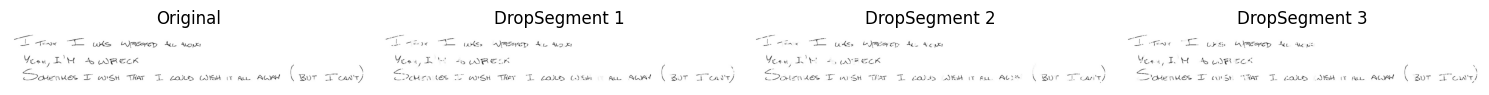

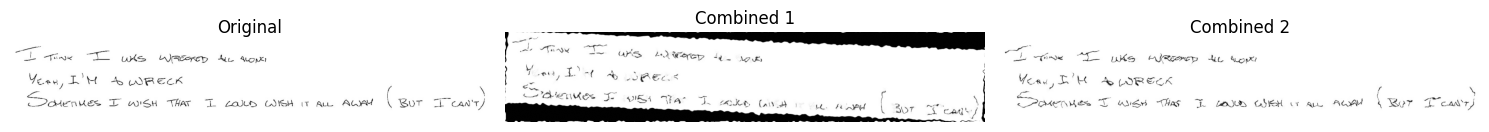

Saved samples to augmented_samples


In [3]:
!pip install --upgrade torch torchvision
!pip install --upgrade imgaug


import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from skimage.transform import rotate, AffineTransform, warp
from skimage.util import random_noise
from skimage.filters import gaussian
from scipy.ndimage import map_coordinates, gaussian_filter
from typing import List, Optional, Tuple, Union


class HandwritingAugmenter:
    """
    Class for augmenting offline handwritten samples for writer verification
    
    Key design considerations:
    - Preserves writer-specific characteristics while adding diversity
    - Focuses on realistic transformations common in handwriting
    - Maintains stroke continuity and overall writing style
    - Implements multiple augmentation techniques with configurable parameters
    """
    
    def __init__(self, seed: Optional[int] = None):
        """
        Initialize the augmenter with optional random seed for reproducibility
        
        Args:
            seed: Random seed for reproducible augmentations
        """
        if seed is not None:
            np.random.seed(seed)
    
    def load_image(self, image_path: str) -> np.ndarray:
        """
        Load an image from a file path
        
        Args:
            image_path: Path to the image file
            
        Returns:
            Loaded image as numpy array
        """
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Failed to load image from {image_path}")
            
        # Ensure image is correctly formatted for handwriting (ink=0, background=255)
        # If the image appears to be inverted, invert it
        if np.mean(image) < 127:  # If average value is low, image might be inverted
            image = 255 - image
            
        return image
    
    def save_image(self, image: np.ndarray, output_path: str) -> None:
        """
        Save an image to a file
        
        Args:
            image: Image to save
            output_path: Path to save the image to
        """
        cv2.imwrite(output_path, image)
    
    def show_images(self, images: List[np.ndarray], titles: List[str]) -> None:
        """
        Display a list of images with titles
        
        Args:
            images: List of images to display
            titles: List of titles for each image
        """
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5))
        if len(images) == 1:
            axes = [axes]
        
        for ax, img, title in zip(axes, images, titles):
            # Ensure proper visualization by setting the correct range
            # For 8-bit grayscale images, use vmin=0, vmax=255
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            ax.set_title(title)
            ax.axis('off')
        
        plt.tight_layout()
        plt.show()
    
    def apply_rotation(self, image: np.ndarray, angle_range: Tuple[float, float] = (-5, 5)) -> np.ndarray:
        """
        Apply random rotation within the specified range
        
        Args:
            image: Input image
            angle_range: Range of rotation angles in degrees (min, max)
            
        Returns:
            Rotated image
        """
        angle = np.random.uniform(angle_range[0], angle_range[1])
        return rotate(image, angle, resize=True, mode='constant', cval=1, preserve_range=True).astype(np.uint8)
    
    def apply_scaling(self, image: np.ndarray, scale_range: Tuple[float, float] = (0.9, 1.1)) -> np.ndarray:
        """
        Apply random scaling within the specified range
        
        Args:
            image: Input image
            scale_range: Range of scaling factors (min, max)
            
        Returns:
            Scaled image
        """
        scale_x = np.random.uniform(scale_range[0], scale_range[1])
        scale_y = np.random.uniform(scale_range[0], scale_range[1])
        
        height, width = image.shape
        new_height, new_width = int(height * scale_y), int(width * scale_x)
        
        # Resize the image
        resized = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_LINEAR)
        
        # Create a new canvas with the original size
        result = np.ones_like(image) * 255
        
        # Calculate placement coordinates
        y_offset = max(0, (height - new_height) // 2)
        x_offset = max(0, (width - new_width) // 2)
        
        # Place the resized image in the center
        y_end = min(y_offset + new_height, height)
        x_end = min(x_offset + new_width, width)
        y_src_end = min(new_height, y_end - y_offset)
        x_src_end = min(new_width, x_end - x_offset)
        
        result[y_offset:y_end, x_offset:x_end] = resized[:y_src_end, :x_src_end]
        
        return result
    
    def apply_shear(self, image: np.ndarray, shear_range: Tuple[float, float] = (-0.05, 0.05)) -> np.ndarray:
        """
        Apply random shear transformation
        
        Args:
            image: Input image
            shear_range: Range of shear factors (min, max)
            
        Returns:
            Sheared image
        """
        shear_factor = np.random.uniform(shear_range[0], shear_range[1])
        transform = AffineTransform(shear=shear_factor)
        
        # Use 'constant' mode with white background (cval=1)
        return warp(image, transform, mode='constant', cval=1, preserve_range=True).astype(np.uint8)
    
    def apply_translation(self, image: np.ndarray, 
                          shift_range: Tuple[float, float] = (-0.05, 0.05)) -> np.ndarray:
        """
        Apply random translation
        
        Args:
            image: Input image
            shift_range: Range of shift as a percentage of image dimensions (min, max)
            
        Returns:
            Translated image
        """
        height, width = image.shape
        
        # Calculate pixel shifts based on image dimensions
        shift_x = int(width * np.random.uniform(shift_range[0], shift_range[1]))
        shift_y = int(height * np.random.uniform(shift_range[0], shift_range[1]))
        
        transform = AffineTransform(translation=(shift_x, shift_y))
        return warp(image, transform, mode='constant', cval=1, preserve_range=True).astype(np.uint8)
    
    def apply_elastic_distortion(self, image: np.ndarray, 
                                alpha: float = 40, 
                                sigma: float = 4) -> np.ndarray:
        """
        Apply elastic distortion to simulate natural handwriting variations
        
        Args:
            image: Input image
            alpha: Intensity of deformation
            sigma: Smoothness of deformation
            
        Returns:
            Elastically distorted image
        """
        height, width = image.shape
        
        # Create random displacement fields
        dx = gaussian_filter((np.random.rand(height, width) * 2 - 1), sigma) * alpha
        dy = gaussian_filter((np.random.rand(height, width) * 2 - 1), sigma) * alpha
        
        # Create meshgrid
        x, y = np.meshgrid(np.arange(width), np.arange(height))
        
        # Displacement indices
        indices = np.reshape(y + dy, (-1, 1)), np.reshape(x + dx, (-1, 1))
        
        # Map coordinates and reshape back
        distorted = map_coordinates(image, indices, order=1, mode='constant', cval=255)
        
        # Ensure output is uint8 with correct range
        return np.clip(distorted.reshape(image.shape), 0, 255).astype(np.uint8)
    
    def apply_thickness_variation(self, image: np.ndarray, 
                                 kernel_range: Tuple[int, int] = (1, 3)) -> np.ndarray:
        """
        Apply random dilation or erosion to simulate different pen thickness
        
        Args:
            image: Input image (0=ink, 255=background)
            kernel_range: Range of kernel sizes for dilation/erosion
            
        Returns:
            Image with varied stroke thickness
        """
        # Invert image for morphological operations (to make ink=255, background=0)
        inverted = cv2.bitwise_not(image)
        
        # Choose between dilation (thicker) and erosion (thinner)
        operation = np.random.choice(['dilate', 'erode'])
        kernel_size = np.random.randint(kernel_range[0], kernel_range[1] + 1)
        kernel = np.ones((kernel_size, kernel_size), np.uint8)
        
        if operation == 'dilate':
            modified = cv2.dilate(inverted, kernel, iterations=1)
        else:  # erode
            modified = cv2.erode(inverted, kernel, iterations=1)
        
        # Invert back
        return cv2.bitwise_not(modified)
    
    def apply_noise(self, image: np.ndarray, 
                   noise_type: str = 'gaussian',
                   var: float = 0.001) -> np.ndarray:
        """
        Apply random noise to simulate scanner noise or paper texture
        
        Args:
            image: Input image
            noise_type: Type of noise ('gaussian', 'pepper', 'salt', 's&p')
            var: Variance of the noise
            
        Returns:
            Noisy image
        """
        # Convert to float in range [0, 1] for random_noise function
        image_norm = image.astype(float) / 255.0
        
        # Add noise
        noisy = random_noise(image_norm, mode=noise_type, var=var)
        
        # Convert back to uint8 and ensure proper range
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)
    
    def apply_contrast_adjustment(self, image: np.ndarray, 
                                 alpha_range: Tuple[float, float] = (0.8, 1.2)) -> np.ndarray:
        """
        Apply random contrast adjustment
        
        Args:
            image: Input image
            alpha_range: Range of contrast adjustment factors
            
        Returns:
            Contrast-adjusted image
        """
        alpha = np.random.uniform(alpha_range[0], alpha_range[1])
        adjusted = cv2.convertScaleAbs(image, alpha=alpha, beta=0)
        return adjusted
    
    def apply_blur(self, image: np.ndarray, sigma_range: Tuple[float, float] = (0.2, 0.7)) -> np.ndarray:
        """
        Apply Gaussian blur to simulate scanning artifacts
        
        Args:
            image: Input image
            sigma_range: Range of Gaussian sigma values
            
        Returns:
            Blurred image
        """
        sigma = np.random.uniform(sigma_range[0], sigma_range[1])
        blurred = gaussian(image, sigma=sigma, preserve_range=True)
        return np.clip(blurred, 0, 255).astype(np.uint8)
    
    def apply_perspective_transform(self, image: np.ndarray, 
                                   distortion_scale: float = 0.05) -> np.ndarray:
        """
        Apply perspective transform to simulate different page orientations during scanning
        
        Args:
            image: Input image
            distortion_scale: Scale of perspective distortion
            
        Returns:
            Perspective-transformed image
        """
        height, width = image.shape
        
        # Get random displacement vectors
        d_scale = distortion_scale * min(height, width)
        
        # Source points (original)
        src = np.array([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], dtype=np.float32)
        
        # Destination points (with random offset)
        dst = src.copy().astype(np.float32)
        dst[0] += np.random.normal(0, d_scale, 2)  # Top-left
        dst[1] += np.random.normal(0, d_scale, 2)  # Top-right
        dst[2] += np.random.normal(0, d_scale, 2)  # Bottom-right
        dst[3] += np.random.normal(0, d_scale, 2)  # Bottom-left
        
        # Apply perspective transform
        transform_matrix = cv2.getPerspectiveTransform(src, dst)
        return cv2.warpPerspective(image, transform_matrix, (width, height), 
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=255)
    
    def apply_drop_segment(self, image: np.ndarray, 
                     segment_size_range: Tuple[int, int] = (3, 8),
                     drop_probability: float = 0.2) -> np.ndarray:
        """
        Selectively remove segments of handwriting while preserving character identity
        
        Args:
            image: Input image (grayscale, ink=0, background=255)
            segment_size_range: Range of segment sizes to drop (min, max)
            drop_probability: Probability of dropping a segment
            
        Returns:
            Image with segments selectively removed
        """
        # Make a copy of the input image
        result = image.copy()
        
        # Find areas with ink (dark pixels)
        # Use binary threshold to identify ink pixels (assuming ink is dark)
        _, binary = cv2.threshold(image, 200, 255, cv2.THRESH_BINARY_INV)
        
        # Find connected components (blobs) in the binary image
        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary)
        
        # Skip the first component (background)
        for i in range(1, num_labels):
            # Get the bounding box of the component
            x, y, w, h, area = stats[i]
            
            # Skip components that are too large (likely whole words or lines)
            # or too small (likely noise or dots)
            if area > 2000 or area < 15:
                continue
                
            # Calculate number of segments based on component width
            num_segments = max(1, w // np.random.randint(segment_size_range[0], segment_size_range[1] + 1))
            
            # Determine segment width
            segment_width = w // num_segments
            
            # For each segment, randomly decide whether to drop it
            for j in range(num_segments):
                if np.random.random() < drop_probability:
                    # Calculate segment boundaries
                    segment_start = x + j * segment_width
                    segment_end = segment_start + segment_width
                    
                    # Create a mask for this segment
                    mask = np.zeros_like(labels)
                    mask[(labels == i) & 
                         (np.arange(mask.shape[1])[np.newaxis, :] >= segment_start) & 
                         (np.arange(mask.shape[1])[np.newaxis, :] < segment_end)] = 1
                    
                    # Set the segment to background color (255 for white background)
                    result[mask == 1] = 255
        
        return result
    
    def augment(self, image: np.ndarray, 
               techniques: Optional[List[str]] = None, 
               num_augmentations: int = 1) -> List[np.ndarray]:
        """
        Apply a combination of augmentation techniques to generate multiple variations
        
        Args:
            image: Input image
            techniques: List of augmentation techniques to use (if None, uses all)
            num_augmentations: Number of augmented samples to generate
            
        Returns:
            List of augmented images
        """
        available_techniques = [
            'rotation', 'scaling', 'shear', 'translation', 
            'elastic_distortion', 'thickness_variation', 'noise',
            'contrast_adjustment', 'blur', 'perspective_transform',
            'drop_segment'
        ]
        
        if techniques is None:
            techniques = available_techniques
        else:
            # Validate techniques
            for tech in techniques:
                if tech not in available_techniques:
                    raise ValueError(f"Unknown augmentation technique: {tech}")
        
        augmented_images = []
        
        for _ in range(num_augmentations):
            # Choose a random subset of techniques (1 to len(techniques))
            num_techniques = np.random.randint(1, min(5, len(techniques) + 1))
            selected_techniques = np.random.choice(techniques, num_techniques, replace=False)
            
            # Apply the selected techniques sequentially
            aug_image = image.copy()
            
            for technique in selected_techniques:
                if technique == 'rotation':
                    aug_image = self.apply_rotation(aug_image)
                elif technique == 'scaling':
                    aug_image = self.apply_scaling(aug_image)
                elif technique == 'shear':
                    aug_image = self.apply_shear(aug_image)
                elif technique == 'translation':
                    aug_image = self.apply_translation(aug_image)
                elif technique == 'elastic_distortion':
                    aug_image = self.apply_elastic_distortion(aug_image)
                elif technique == 'thickness_variation':
                    aug_image = self.apply_thickness_variation(aug_image)
                elif technique == 'noise':
                    aug_image = self.apply_noise(aug_image)
                elif technique == 'contrast_adjustment':
                    aug_image = self.apply_contrast_adjustment(aug_image)
                elif technique == 'blur':
                    aug_image = self.apply_blur(aug_image)
                elif technique == 'perspective_transform':
                    aug_image = self.apply_perspective_transform(aug_image)
                elif technique == 'drop_segment':
                    aug_image = self.apply_drop_segment(aug_image)
            
            augmented_images.append(aug_image)
        
        return augmented_images
    
    def augment_dataset(self, input_dir: str, output_dir: str, 
                       techniques: Optional[List[str]] = None,
                       augmentations_per_image: int = 5) -> None:
        """
        Augment an entire dataset of images
        
        Args:
            input_dir: Directory containing the original images
            output_dir: Directory to save augmented images
            techniques: List of augmentation techniques to use
            augmentations_per_image: Number of augmentations to generate per input image
        """
        # Create output directory if it doesn't exist
        os.makedirs(output_dir, exist_ok=True)
        
        # Get list of image files
        image_files = [f for f in os.listdir(input_dir) 
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]
        
        for img_file in image_files:
            # Load image
            img_path = os.path.join(input_dir, img_file)
            image = self.load_image(img_path)
            
            # Generate augmentations
            augmented_images = self.augment(image, techniques, augmentations_per_image)
            
            # Save augmented images
            base_name = os.path.splitext(img_file)[0]
            
            for i, aug_img in enumerate(augmented_images):
                output_path = os.path.join(output_dir, f"{base_name}_aug_{i+1}.png")
                self.save_image(aug_img, output_path)


# Example usage
if __name__ == "__main__":
    augmenter = HandwritingAugmenter(seed=42)
    
    # 1. Demonstrate augmentation on a single image
    sample_image_path = "/workspaces/hotel_booking_demand_analysis/processed_no_grid.jpg"  # Update with your sample path
    
    try:
        # Try to load the sample image
        sample_image = augmenter.load_image(sample_image_path)
        
        # Generate augmentations with various techniques
        regular_augmentations = augmenter.augment(
            sample_image,
            techniques=[
                'rotation', 'scaling', 'shear', 'elastic_distortion', 
                'thickness_variation', 'noise'
            ],
            num_augmentations=3
        )
        
        # Generate specific drop_segment augmentations
        drop_segment_augmentations = augmenter.augment(
            sample_image,
            techniques=['drop_segment'],
            num_augmentations=3
        )
        
        # Combine regular and drop_segment augmentations
        combined_augmentations = augmenter.augment(
            sample_image,
            techniques=['drop_segment', 'rotation', 'elastic_distortion'],
            num_augmentations=2
        )
        
        # Show original and all augmented images
        augmenter.show_images(
            [sample_image] + drop_segment_augmentations,
            ["Original"] + [f"DropSegment {i+1}" for i in range(len(drop_segment_augmentations))]
        )
        
        # Show combined augmentations
        augmenter.show_images(
            [sample_image] + combined_augmentations,
            ["Original"] + [f"Combined {i+1}" for i in range(len(combined_augmentations))]
        )
        
        # Save visualization as a reference
        output_dir = "augmented_samples"
        os.makedirs(output_dir, exist_ok=True)
        
        # Save individual samples
        cv2.imwrite(os.path.join(output_dir, "original.png"), sample_image)
        
        for i, img in enumerate(drop_segment_augmentations):
            cv2.imwrite(os.path.join(output_dir, f"drop_segment_{i+1}.png"), img)
            
        for i, img in enumerate(combined_augmentations):
            cv2.imwrite(os.path.join(output_dir, f"combined_{i+1}.png"), img)
            
        print(f"Saved samples to {output_dir}")
        
    except Exception as e:
        print(f"Could not demonstrate on sample image: {e}")
        print("To use this augmenter on your own data:")
        print("1. Create an instance: augmenter = HandwritingAugmenter()")
        print("2. Augment a single image:")
        print("   - Load your image: image = augmenter.load_image('path/to/image.png')")
        print("   - Generate augmentations: augmented = augmenter.augment(image, num_augmentations=5)")
        print("3. Augment an entire dataset:")
        print("   - augmenter.augment_dataset('input_dir', 'output_dir', augmentations_per_image=5)")